In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [3]:
# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [6]:
# Step 4: Load Dataset

import pandas as pd

df = pd.read_csv("merged_youtube_live.csv", low_memory=False)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [7]:
# Step 5: Understand Dataset

print("First 5 Rows of Dataset:")

display(df.head())

First 5 Rows of Dataset:


,"""No.""","""Time""","""Source""","""Destination""","""Protocol""","""Length""","""Info"""
0,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""1278""","""Client Hello",PKN: 1,"CID: 4472406183105229454"""
1,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""936""","""Payload (Encrypted)",PKN: 2,"CID: 4472406183105229454"""
2,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""817""","""Payload (Encrypted)",PKN: 3,"CID: 4472406183105229454"""
3,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""931""","""Payload (Encrypted)",PKN: 4,"CID: 4472406183105229454"""
4,"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""931""","""Payload (Encrypted)",PKN: 5,"CID: 4472406183105229454"""


In [8]:

import csv
import re
import ipaddress

file_path = "merged_youtube_live.csv"

# কয়েকটি আলাদা জায়গা থেকে Sample নেওয়া
sample_lines = [2, 3, 526769, 2000001, 2000002, 2801516]

def clean(value):
    return value.strip().strip('"').strip()

def valid_ip(value):
    try:
        ipaddress.ip_address(value)
        return True
    except ValueError:
        return False

time_pattern = re.compile(
    r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:\.\d+)?$"
)

with open(file_path, "r", encoding="utf-8",
          errors="replace", newline="") as f:

    for line_number, row in enumerate(csv.reader(f), start=1):

        if line_number not in sample_lines:
            continue

        values = [clean(x) for x in row]

        if len(values) >= 7 and time_pattern.match(values[1]):
            layout = "Complete"
            no, time, source, destination, protocol, length = values[:6]
            info = ",".join(values[6:])

        elif len(values) >= 6 and time_pattern.match(values[0]):
            layout = "Time available, No missing"
            no = ""
            time, source, destination, protocol, length = values[:5]
            info = ",".join(values[5:])

        elif len(values) >= 5:
            layout = "Time and No missing"
            no = ""
            time = ""
            source, destination, protocol, length = values[:4]
            info = ",".join(values[4:])

        else:
            print("Invalid Row:", line_number, values)
            continue

        print("\nRow:", line_number)
        print("Layout:", layout)
        print("Time:", time)
        print("Source:", source)
        print("Destination:", destination)
        print("Protocol:", protocol)
        print("Length:", length)
        print("Info:", info)
        print("Valid Source IP:", valid_ip(source))
        print("Valid Destination IP:", valid_ip(destination))
        print("Valid Length:", length.isdigit())



Row: 2
Layout: Time and No missing
Time: 
Source: 10.215.173.1
Destination: 142.251.72.7
Protocol: GQUIC
Length: 1278
Info: Client Hello,PKN: 1,CID: 4472406183105229454
Valid Source IP: True
Valid Destination IP: True
Valid Length: True

Row: 3
Layout: Time and No missing
Time: 
Source: 10.215.173.1
Destination: 142.251.72.7
Protocol: GQUIC
Length: 936
Info: Payload (Encrypted),PKN: 2,CID: 4472406183105229454
Valid Source IP: True
Valid Destination IP: True
Valid Length: True


In [11]:

file_path = "merged_youtube_live.csv"
sample_lines = {526769, 2000001, 2000002, 2801516}

with open(file_path, "r", encoding="utf-8",
          errors="replace") as f:

    for line_number, line in enumerate(f, start=1):
        if line_number in sample_lines:
            print(f"\nPhysical Line: {line_number}")
            print(line.strip())

        if line_number > max(sample_lines):
            break


In [12]:

file_path = "merged_youtube_live.csv"

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    for i in range(5):
        print(f.readline().strip())

print("\nFile reading successful!")


"""No.""","""Time""","""Source""","""Destination""","""Protocol""","""Length""","""Info"""
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""1278""","""Client Hello", PKN: 1," CID: 4472406183105229454"""
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""936""","""Payload (Encrypted)", PKN: 2," CID: 4472406183105229454"""
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""817""","""Payload (Encrypted)", PKN: 3," CID: 4472406183105229454"""
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""931""","""Payload (Encrypted)", PKN: 4," CID: 4472406183105229454"""

File reading successful!


In [15]:

file_path = "merged_youtube_live.csv"

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    for line_number, line in enumerate(f, start=1):
        if line_number in [526769, 2000001, 2000002]:
            print("\nRow Number:", line_number)
            print(line.strip())


In [17]:
file_path = "merged_youtube_live.csv"

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

total_lines = len(lines)
print("Total lines:", total_lines)

# Ensure we only check lines that actually exist in the file
for n in [526769, 2000001, 2000002]:
    print("\nLine:", n)
    if n <= total_lines:
        print(lines[n-1][:500])
    else:
        print(f"Line {n} does not exist (File only has {total_lines} lines)")

Total lines: 151840

Line: 526769
Line 526769 does not exist (File only has 151840 lines)

Line: 2000001
Line 2000001 does not exist (File only has 151840 lines)

Line: 2000002
Line 2000002 does not exist (File only has 151840 lines)


In [18]:

file_path = "merged_youtube_live.csv"

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

print("Total Lines:", len(lines))

for n in [1, 2, 3, len(lines)//2, len(lines)-1, len(lines)]:
    print(f"\nLine {n}:")
    print(lines[n-1].strip()[:300])


Total Lines: 151840

Line 1:
"""No.""","""Time""","""Source""","""Destination""","""Protocol""","""Length""","""Info"""

Line 2:
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""1278""","""Client Hello", PKN: 1," CID: 4472406183105229454"""

Line 3:
"""10.215.173.1""","""142.251.72.7""","""GQUIC""","""936""","""Payload (Encrypted)", PKN: 2," CID: 4472406183105229454"""

Line 75920:
"""211.114.64.76""","""10.215.173.1""","""GQUIC""","""1278""","""Payload (Encrypted)"," PKN: 2420""",

Line 151839:
"""211.114.64.76""","""10.215.173.1""","""GQUIC""","""1278""","""Payload (Encrypted)"," PKN: 41173""",

Line 151840:
"""211.114.64.76""","""10.215.173.1"""


In [19]:

import re
import ipaddress

file_path = "merged_youtube_live.csv"

valid_rows = 0
invalid_rows = 0
protocols = {}

with open(file_path, "r", encoding="utf-8", errors="replace") as f:
    next(f)  # Header বাদ

    for line in f:
        line = line.strip()

        pattern = r'^"""([^"]*)""","""([^"]*)""","""([^"]*)""","""(\d+)""","""?(.*)$'
        match = re.match(pattern, line)

        if match:
            source, destination, protocol, length, info = match.groups()

            try:
                ipaddress.ip_address(source)
                ipaddress.ip_address(destination)

                if protocol and int(length) > 0:
                    valid_rows += 1
                    protocols[protocol] = protocols.get(protocol, 0) + 1
                else:
                    invalid_rows += 1

            except ValueError:
                invalid_rows += 1
        else:
            invalid_rows += 1

print("Valid Rows:", valid_rows)
print("Invalid Rows:", invalid_rows)
print("\nProtocol Counts:")
print(protocols)


Valid Rows: 151833
Invalid Rows: 6

Protocol Counts:
{'GQUIC': 151833}


In [20]:

import re
import csv
import ipaddress

input_file = "merged_youtube_live.csv"
output_file = "cleaned_gquic_dataset.csv"

valid_rows = 0
invalid_rows = 0

with open(input_file, "r", encoding="utf-8",
          errors="replace") as infile, \
     open(output_file, "w", newline="", encoding="utf-8") as outfile:

    writer = csv.writer(outfile)

    # Clean Dataset-এর Header
    writer.writerow([
        "Source", "Destination", "Protocol", "Length", "Info"
    ])

    next(infile)  # পুরোনো Header বাদ

    for line in infile:
        line = line.strip()

        pattern = r'^"""([^"]*)""","""([^"]*)""","""([^"]*)""","""(\d+)""","""?(.*)$'
        match = re.match(pattern, line)

        if not match:
            invalid_rows += 1
            continue

        source, destination, protocol, length, info = match.groups()

        try:
            ipaddress.ip_address(source)
            ipaddress.ip_address(destination)

            if not protocol or int(length) <= 0:
                invalid_rows += 1
                continue

            # Info-র শেষের অতিরিক্ত quotation mark সরানো
            info = info.strip()
            if info.endswith('"""'):
                info = info[:-3]

            writer.writerow([
                source, destination, protocol, int(length), info
            ])

            valid_rows += 1

        except ValueError:
            invalid_rows += 1

print("Dataset Cleaning Completed!")
print("Valid Rows:", valid_rows)
print("Invalid Rows Removed:", invalid_rows)
print("Clean Dataset Saved:", output_file)


Dataset Cleaning Completed!
Valid Rows: 151833
Invalid Rows Removed: 6
Clean Dataset Saved: cleaned_gquic_dataset.csv


In [21]:

import pandas as pd

df = pd.read_csv("cleaned_gquic_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (151833, 5)

First 5 Rows:
         Source   Destination Protocol  Length  \
0  10.215.173.1  142.251.72.7    GQUIC    1278   
1  10.215.173.1  142.251.72.7    GQUIC     936   
2  10.215.173.1  142.251.72.7    GQUIC     817   
3  10.215.173.1  142.251.72.7    GQUIC     931   
4  10.215.173.1  142.251.72.7    GQUIC     931   

                                                Info  
0   Client Hello", PKN: 1," CID: 4472406183105229454  
1  Payload (Encrypted)", PKN: 2," CID: 4472406183...  
2  Payload (Encrypted)", PKN: 3," CID: 4472406183...  
3  Payload (Encrypted)", PKN: 4," CID: 4472406183...  
4  Payload (Encrypted)", PKN: 5," CID: 4472406183...  

Column Names:
['Source', 'Destination', 'Protocol', 'Length', 'Info']

Data Types:
Source         object
Destination    object
Protocol       object
Length          int64
Info           object
dtype: object


In [22]:

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values in Each Column:
Source         0
Destination    0
Protocol       0
Length         0
Info           0
dtype: int64

Total Missing Values:
0


In [23]:

print("Total Duplicate Rows:")
print(df.duplicated().sum())


Total Duplicate Rows:
69876


In [24]:

duplicates = df[df.duplicated(keep=False)]

print("Total Duplicate Rows:", len(duplicates))

print("\nFirst 10 Duplicate Rows:")
print(duplicates.head(10))


Total Duplicate Rows: 116592

First 10 Duplicate Rows:
            Source   Destination Protocol  Length  \
180  211.114.64.76  10.215.173.1    GQUIC    1278   
194  211.114.64.76  10.215.173.1    GQUIC    1278   
196  211.114.64.76  10.215.173.1    GQUIC    1278   
197  211.114.64.76  10.215.173.1    GQUIC    1278   
201  211.114.64.76  10.215.173.1    GQUIC    1278   
202  211.114.64.76  10.215.173.1    GQUIC    1278   
624  211.114.64.76  10.215.173.1    GQUIC    1278   
626  211.114.64.76  10.215.173.1    GQUIC    1278   
628  211.114.64.76  10.215.173.1    GQUIC    1278   
630  211.114.64.76  10.215.173.1    GQUIC    1278   

                                   Info  
180   Payload (Encrypted)"," PKN: 2""",  
194   Payload (Encrypted)"," PKN: 5""",  
196   Payload (Encrypted)"," PKN: 6""",  
197   Payload (Encrypted)"," PKN: 7""",  
201  Payload (Encrypted)"," PKN: 11""",  
202  Payload (Encrypted)"," PKN: 12""",  
624  Payload (Encrypted)"," PKN: 18""",  
626  Payload (Encrypted)"

In [25]:

exact_duplicates = df[df.duplicated(keep=False)]

print("First 10 Exact Duplicate Rows:")
print(
    exact_duplicates.sort_values(
        by=["Source", "Destination", "Protocol", "Length", "Info"]
    ).head(10).to_string(index=False)
)


First 10 Exact Duplicate Rows:
      Source   Destination Protocol  Length                                                      Info
10.215.173.1 211.114.64.76    GQUIC      57   Payload (Encrypted)", PKN: 1," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57   Payload (Encrypted)", PKN: 1," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57   Payload (Encrypted)", PKN: 1," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57  Payload (Encrypted)", PKN: 10," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57  Payload (Encrypted)", PKN: 10," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57  Payload (Encrypted)", PKN: 10," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57  Payload (Encrypted)", PKN: 10," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57 Payload (Encrypted)", PKN: 100," CID: 4212981106657580395
10.215.173.1 211.114.64.76    GQUIC      57 Payload

In [26]:

print("Statistical Summary of Dataset:")
print(df.describe())


Statistical Summary of Dataset:
              Length
count  151833.000000
mean     1149.178637
std       337.665598
min        45.000000
25%      1278.000000
50%      1278.000000
75%      1278.000000
max      1278.000000


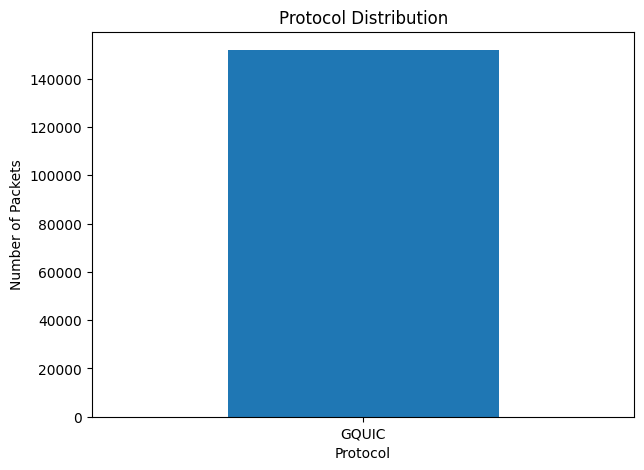

Protocol
GQUIC    151833
Name: count, dtype: int64


In [27]:

import matplotlib.pyplot as plt

protocol_counts = df["Protocol"].value_counts()

plt.figure(figsize=(7, 5))
protocol_counts.plot(kind="bar")

plt.title("Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.xticks(rotation=0)
plt.show()

print(protocol_counts)


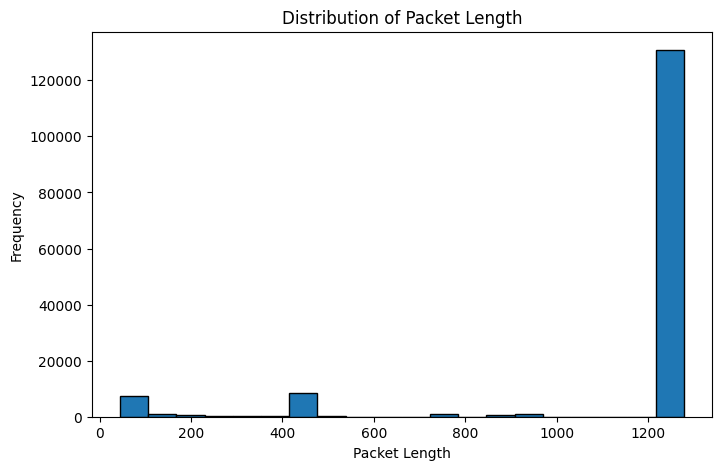

In [28]:

plt.figure(figsize=(8, 5))

plt.hist(df["Length"], bins=20, edgecolor="black")

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()


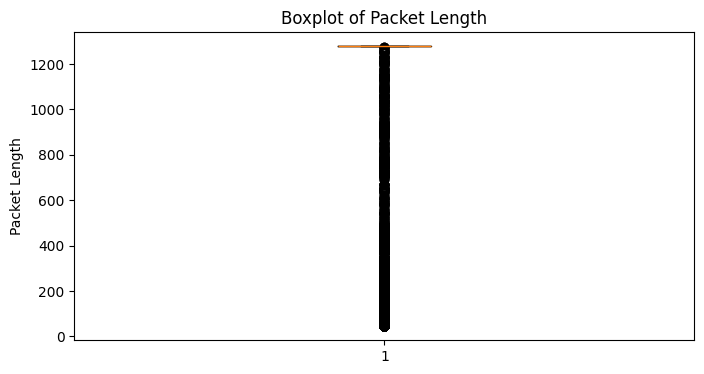

In [29]:

plt.figure(figsize=(8, 4))

plt.boxplot(df["Length"])

plt.title("Boxplot of Packet Length")
plt.ylabel("Packet Length")

plt.show()


In [30]:

print("Unique Packet Lengths:")
print(df["Length"].nunique())

print("\nMost Common Packet Lengths:")
print(df["Length"].value_counts().head(10))


Unique Packet Lengths:
741

Most Common Packet Lengths:
Length
1278    130749
461       4255
447       2435
59        1637
57        1048
49         850
60         716
52         661
937        550
120        528
Name: count, dtype: int64


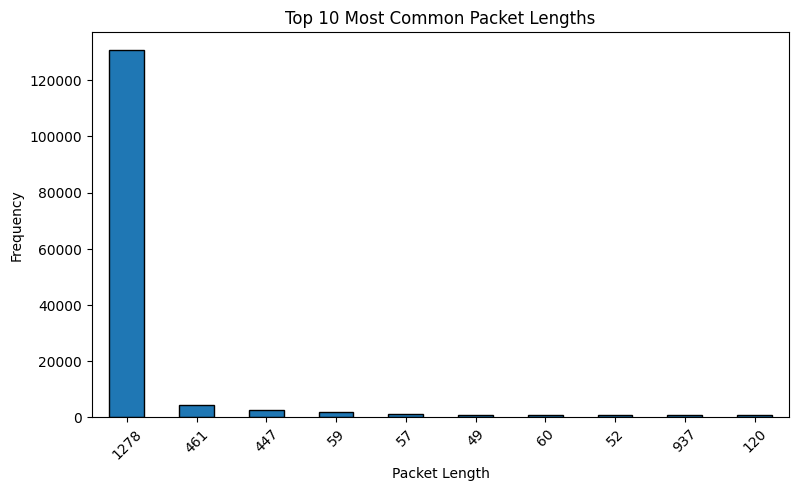

In [31]:

top_lengths = df["Length"].value_counts().head(10)

plt.figure(figsize=(9, 5))

top_lengths.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Most Common Packet Lengths")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()


In [32]:

print("First 10 Info Values:")
print(df["Info"].head(10).to_string(index=False))


First 10 Info Values:
  Client Hello", PKN: 1," CID: 4472406183105229454
Payload (Encrypted)", PKN: 2," CID: 44724061831...
Payload (Encrypted)", PKN: 3," CID: 44724061831...
Payload (Encrypted)", PKN: 4," CID: 44724061831...
Payload (Encrypted)", PKN: 5," CID: 44724061831...
     Rejection", PKN: 1," CID: 4472406183105229454
Payload (Encrypted)", PKN: 2," CID: 44724061831...
  Client Hello", PKN: 6," CID: 4472406183105229454
Payload (Encrypted)", PKN: 7," CID: 44724061831...
Payload (Encrypted)", PKN: 8," CID: 44724061831...


In [33]:

import re

df["PKN"] = df["Info"].str.extract(r"PKN:\s*(\d+)")

df["PKN"] = pd.to_numeric(df["PKN"], errors="coerce")

print("First 10 PKN Values:")
print(df["PKN"].head(10))

print("\nMissing PKN Values:")
print(df["PKN"].isnull().sum())

print("\nTotal Unique PKN Values:")
print(df["PKN"].nunique())


First 10 PKN Values:
0    1
1    2
2    3
3    4
4    5
5    1
6    2
7    6
8    7
9    8
Name: PKN, dtype: int64

Missing PKN Values:
0

Total Unique PKN Values:
65530


In [34]:

print("Correlation between PKN and Length:")
print(df["PKN"].corr(df["Length"]))

print("\nAverage Length for First 10 PKN Values:")
print(
    df.groupby("PKN")["Length"]
    .mean()
    .head(10)
)


Correlation between PKN and Length:
0.2030760420187839

Average Length for First 10 PKN Values:
PKN
0    409.440000
1    628.111111
2    590.177778
3    249.500000
4    444.288889
5    352.311111
6    388.700000
7    313.433333
8    235.159091
9    175.722222
Name: Length, dtype: float64


In [35]:

print("Minimum PKN:", df["PKN"].min())
print("Maximum PKN:", df["PKN"].max())

print("\nFirst 10 PKN Values:")
print(df["PKN"].head(10).tolist())

print("\nPKN and Length:")
print(df[["PKN", "Length"]].head(10).to_string(index=False))


Minimum PKN: 0
Maximum PKN: 65535

First 10 PKN Values:
[1, 2, 3, 4, 5, 1, 2, 6, 7, 8]

PKN and Length:
 PKN  Length
   1    1278
   2     936
   3     817
   4     931
   5     931
   1    1278
   2    1278
   6    1278
   7    1278
   8     467


In [36]:

print("Packets with PKN = 0:")
print((df["PKN"] == 0).sum())

print("\nPackets with PKN = 1:")
print((df["PKN"] == 1).sum())

print("\nPackets with PKN = 65535:")
print((df["PKN"] == 65535).sum())


Packets with PKN = 0:
25

Packets with PKN = 1:
90

Packets with PKN = 65535:
1


In [37]:

X = df[["PKN"]]
y = df["Length"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


Input Features:
   PKN
0    1
1    2
2    3
3    4
4    5

Target Values:
0    1278
1     936
2     817
3     931
4     931
Name: Length, dtype: int64

X Shape: (151833, 1)
y Shape: (151833,)


In [38]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Data: (121466, 1)
Testing Data: (30367, 1)
Training Target: (121466,)
Testing Target: (30367,)


In [39]:

from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree Model
dt_model = DecisionTreeRegressor(random_state=42)

# Train Model
dt_model.fit(X_train, y_train)

# Prediction
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Regression Model Trained Successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_dt[:10])


Decision Tree Regression Model Trained Successfully!

First 10 Actual Values:
[1278 1278 1278 1278 1278 1278 1278  461 1278 1278]

First 10 Predicted Values:
[1278.  1278.  1278.  1278.  1278.  1278.  1278.  1278.   869.5  461. ]


In [40]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae_dt = mean_absolute_error(y_test, y_pred_dt)

mse_dt = mean_squared_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression Evaluation")
print("-----------------------------------")
print("MAE :", mae_dt)
print("MSE :", mse_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)


Decision Tree Regression Evaluation
-----------------------------------
MAE : 161.73777955899266
MSE : 125738.182639199
RMSE: 354.5958017788691
R2 Score: -0.11149152672039331


In [41]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regression Model Trained Successfully!")

print("\nFirst 10 Predicted Values:")
print(y_pred_rf[:10])


Random Forest Regression Model Trained Successfully!

First 10 Predicted Values:
[1278.         1278.         1278.         1135.54       1278.
 1278.         1278.         1278.          946.57033333  804.14      ]


In [42]:

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Evaluation")
print("-----------------------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)


Random Forest Regression Evaluation
-----------------------------------
MAE : 159.0259643907539
MSE : 103337.37266264965
RMSE: 321.4613081891033
R2 Score: 0.0865255748314322


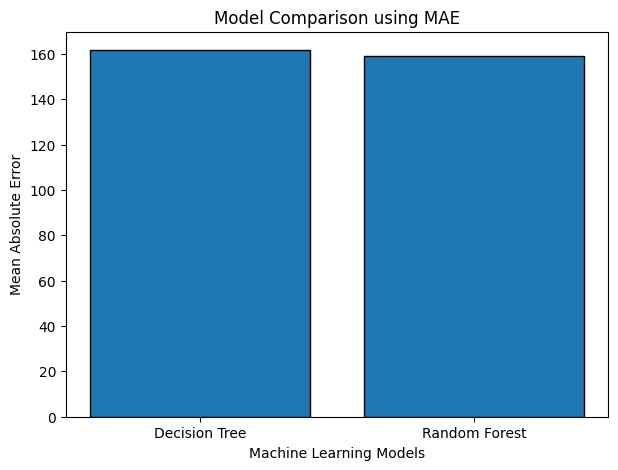

In [43]:

models = ["Decision Tree", "Random Forest"]
mae_values = [mae_dt, mae_rf]

plt.figure(figsize=(7, 5))

plt.bar(models, mae_values, edgecolor="black")

plt.title("Model Comparison using MAE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")

plt.show()


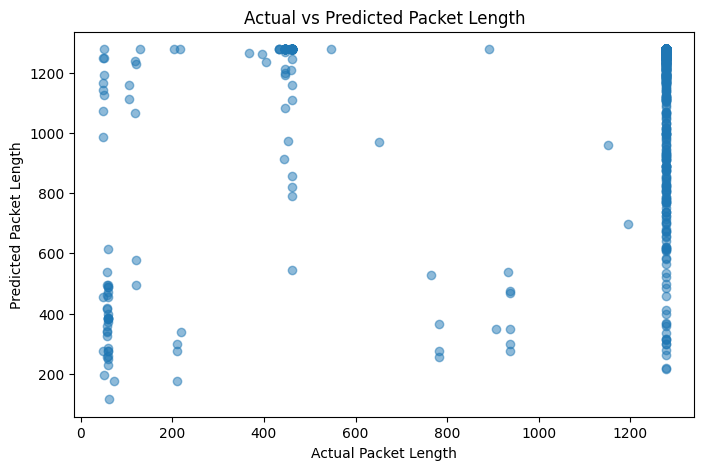

In [44]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test[:1000], y_pred_rf[:1000], alpha=0.5)

plt.title("Actual vs Predicted Packet Length")
plt.xlabel("Actual Packet Length")
plt.ylabel("Predicted Packet Length")

plt.show()
